In [9]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr

CITY = "Bengaluru"

PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "regions"
OUTPUT_DIR = PROJECT_DIR / f"series2_outputs/{CITY.lower()}"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

data = pd.read_csv(DATA_DIR / f"{CITY}_cell_year_2015_2025.csv")

data["year"] = pd.to_numeric(data["year"], errors="coerce")

VARIABLES = ["lst_c", "ndbi", "ndvi"]
YEARS = list(range(2015, 2026))
MAP_YEARS = [2015, 2020, 2025]

sns.set_theme(style="whitegrid")

print(f"City: {CITY}")
print(f"Records: {len(data):,}")
print(f"Unique grid cells: {data['grid_id'].nunique():,}")
print(f"Years present: {sorted(data['year'].dropna().unique().astype(int))}")
print(f"Output directory: {OUTPUT_DIR}")
display(data.head())


City: Bengaluru
Records: 158,840
Unique grid cells: 14,440
Years present: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Output directory: d:\sparkle\urban heat lockin\series2_outputs\bengaluru


,grid_id,city_id,city,year,lst_c,ndvi,ndbi,n_obs_mean,l8_scenes,l9_scenes,sensor_mix
0,Bengaluru_24854_5463,Bengaluru,Bengaluru,2015,38.873372,0.331204,0.048840,3.000000,8,0,Landsat 8
1,Bengaluru_24854_5463,Bengaluru,Bengaluru,2016,45.067587,0.315029,0.058211,5.082973,9,0,Landsat 8
2,Bengaluru_24854_5463,Bengaluru,Bengaluru,2017,43.655641,0.348468,0.032909,6.000000,8,0,Landsat 8
3,Bengaluru_24854_5463,Bengaluru,Bengaluru,2018,34.941321,0.373778,0.001816,5.121435,8,0,Landsat 8
4,Bengaluru_24854_5463,Bengaluru,Bengaluru,2019,41.415558,0.360569,0.008355,6.000000,7,0,Landsat 8


,records,unique_cells,mean_observations
year,,,
2015,14440,14440,5.187336
2016,14440,14440,5.578773
2017,14440,14440,5.557437
2018,14440,14440,5.415799
2019,14440,14440,5.750332
2020,14440,14440,5.283121
2021,14440,14440,4.354845
2022,14440,14440,7.483977
2023,14440,14440,7.994098


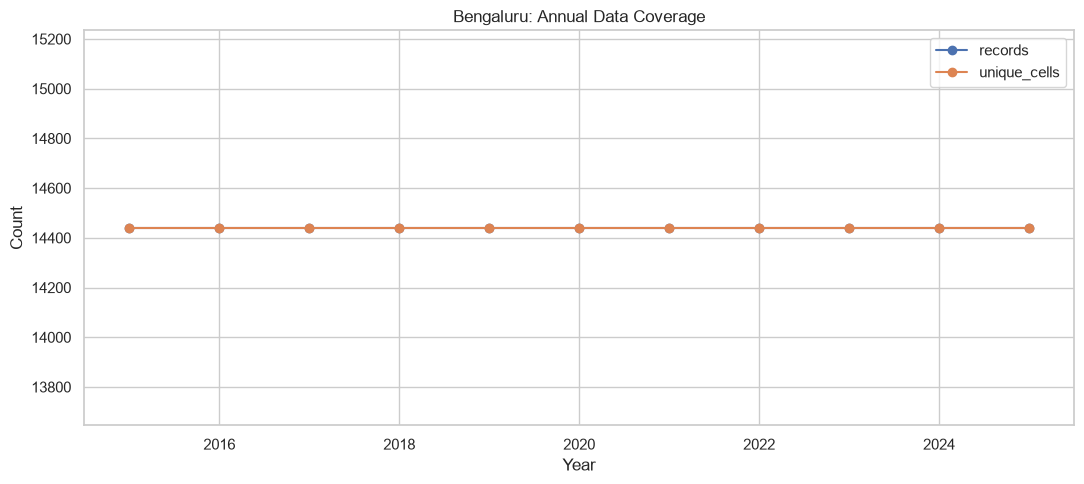

,missing_count,missing_percent
lst_c,0,0.0
ndbi,0,0.0
ndvi,0,0.0
n_obs_mean,0,0.0


In [10]:

# Number of records and unique grid cells per year
year_coverage = (
    data.groupby("year")
    .agg(
        records=("grid_id", "size"),
        unique_cells=("grid_id", "nunique"),
        mean_observations=("n_obs_mean", "mean")
    )
    .reindex(YEARS)
)

display(year_coverage)

ax = year_coverage[["records", "unique_cells"]].plot(
    figsize=(11, 5), marker="o"
)
ax.set_title(f"{CITY}: Annual Data Coverage")
ax.set_xlabel("Year")
ax.set_ylabel("Count")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_annual_coverage.png", dpi=200)
plt.show()

# Missing values
missing = data[VARIABLES + ["n_obs_mean"]].isna().sum().to_frame("missing_count")
missing["missing_percent"] = missing["missing_count"] / len(data) * 100
display(missing)

missing.to_csv(OUTPUT_DIR / "missing_values.csv")


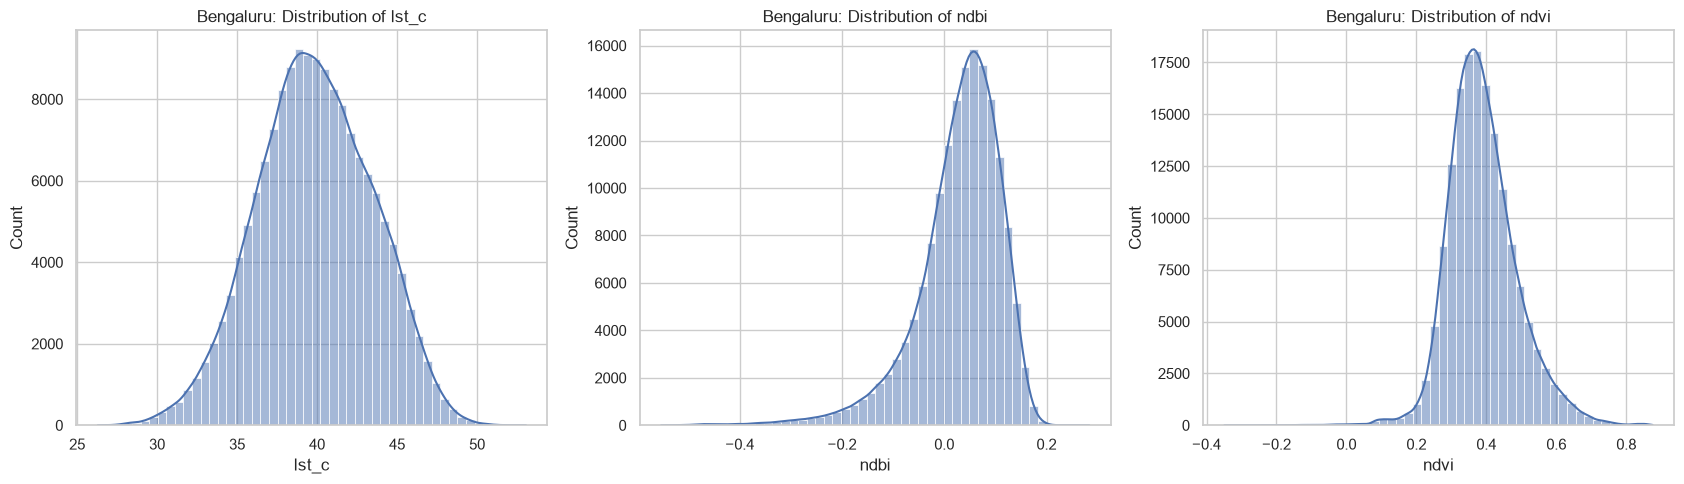

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
lst_c,158840.0,39.861818,3.611607,26.292630,31.444968,33.898883,37.392458,39.812460,42.435353,45.766330,47.630375,53.052738
ndbi,158840.0,0.028523,0.083647,-0.553907,-0.257677,-0.127404,-0.010133,0.042196,0.085319,0.134547,0.160516,0.283648
ndvi,158840.0,0.390119,0.098566,-0.348667,0.172689,0.254410,0.325461,0.380048,0.444970,0.568127,0.665673,0.875150


In [11]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, variable in zip(axes, VARIABLES):
    sns.histplot(
        data=data,
        x=variable,
        bins=50,
        kde=True,
        ax=ax
    )
    ax.set_title(f"{CITY}: Distribution of {variable}")
    ax.set_xlabel(variable)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_variable_distributions.png", dpi=200)
plt.show()

display(data[VARIABLES].describe(percentiles=[
    0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99
]).T)


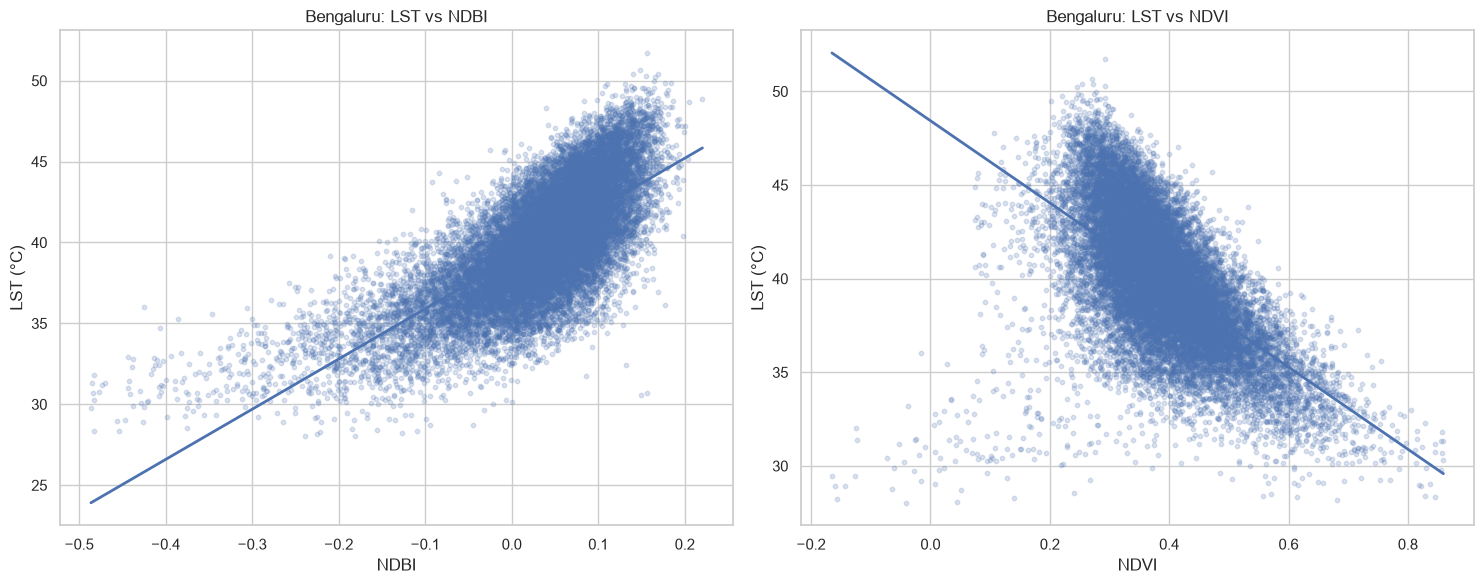

In [12]:

plot_data = data.dropna(subset=["lst_c", "ndbi", "ndvi"]).copy()

plot_sample = plot_data.sample(
    n=min(20000, len(plot_data)),
    random_state=42
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI")
]:
    sns.regplot(
        data=plot_sample,
        x=xvar,
        y="lst_c",
        ax=ax,
        scatter_kws={"alpha": 0.2, "s": 10},
        line_kws={"linewidth": 2},
        ci=None
    )
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel(xvar.upper())
    ax.set_ylabel("LST (°C)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_lst_relationships.png", dpi=200)
plt.show()


In [13]:

PAIRS = [
    ("lst_c", "ndbi"),
    ("lst_c", "ndvi"),
    ("ndbi", "ndvi")
]

def calculate_correlations(df):
    results = []

    for x, y in PAIRS:
        pair = df[[x, y]].replace([np.inf, -np.inf], np.nan).dropna()
        n = len(pair)

        result = {
            "variable_1": x,
            "variable_2": y,
            "n": n,
            "pearson_r": np.nan,
            "pearson_p": np.nan,
            "spearman_rho": np.nan,
            "spearman_p": np.nan
        }

        if n >= 3 and pair[x].nunique() > 1 and pair[y].nunique() > 1:
            r, p = pearsonr(pair[x], pair[y])
            rho, sp = spearmanr(pair[x], pair[y])

            result.update({
                "pearson_r": r,
                "pearson_p": p,
                "spearman_rho": rho,
                "spearman_p": sp
            })

        results.append(result)

    return pd.DataFrame(results)

pooled_corr = calculate_correlations(data)
display(pooled_corr)
pooled_corr.to_csv(OUTPUT_DIR / "pooled_correlations.csv", index=False)

annual_corr = pd.concat(
    [
        calculate_correlations(group).assign(year=int(year))
        for year, group in data.groupby("year")
    ],
    ignore_index=True
)

display(annual_corr)
annual_corr.to_csv(OUTPUT_DIR / "annual_correlations.csv", index=False)


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,lst_c,ndbi,158840,0.716102,0.0,0.710460,0.0
1,lst_c,ndvi,158840,-0.601183,0.0,-0.634096,0.0
2,ndbi,ndvi,158840,-0.717649,0.0,-0.755099,0.0


,variable_1,variable_2,n,pearson_r,pearson_p,spearman_rho,spearman_p,year
0,lst_c,ndbi,14440,0.689332,0.0,0.638461,0.0,2015
1,lst_c,ndvi,14440,-0.589589,0.0,-0.607396,0.0,2015
2,ndbi,ndvi,14440,-0.768195,0.0,-0.781414,0.0,2015
3,lst_c,ndbi,14440,0.717936,0.0,0.680899,0.0,2016
4,lst_c,ndvi,14440,-0.550417,0.0,-0.555621,0.0,2016
5,ndbi,ndvi,14440,-0.756459,0.0,-0.764043,0.0,2016
6,lst_c,ndbi,14440,0.712172,0.0,0.675677,0.0,2017
7,lst_c,ndvi,14440,-0.573414,0.0,-0.582922,0.0,2017
8,ndbi,ndvi,14440,-0.748216,0.0,-0.709192,0.0,2017
9,lst_c,ndbi,14440,0.682449,0.0,0.685444,0.0,2018


lst_c                                  ndbi                      \
           mean     median       std  count      mean    median       std   
year                                                                        
2015  37.978476  38.029601  2.250612  14440  0.001653  0.011986  0.081341   
2016  42.196476  42.462681  3.290295  14440  0.041773  0.054881  0.077887   
2017  41.600478  41.611764  2.867898  14440  0.058258  0.071939  0.080511   
2018  36.226155  36.026792  2.778408  14440 -0.000396  0.013848  0.085141   
2019  40.677001  40.779645  3.357832  14440  0.045779  0.058580  0.077574   
2020  41.338501  41.707356  3.065884  14440  0.050042  0.061711  0.073196   
2021  39.847646  40.029930  3.124474  14440  0.047697  0.058401  0.072271   
2022  37.573612  37.846165  2.737327  14440  0.008133  0.020828  0.080086   
2023  38.731295  38.854810  3.038244  14440 -0.009479  0.004541  0.089254   
2024  43.555954  43.814813  2.844874  14440  0.063352  0.075233  0.073190   
2025  38.754401  38.956237  2.631650  14440  0.006944  0.018215  0.083282   

                 ndvi                             
      count      mean    median       std  count  
year                                              
2015  14440  0.425196  0.417468  0.093463  14440  
2016  14440  0.369760  0.361178  0.087217  14440  
2017  14440  0.361042  0.350766  0.088371  14440  
2018  14440  0.422545  0.412637  0.101569  14440  
2019  14440  0.351282  0.341755  0.088705  14440  
2020  14440  0.371408  0.362881  0.086963  14440  
2021  14440  0.381755  0.374673  0.083586  14440  
2022  14440  0.423540  0.417506  0.090171  14440  
2023  14440  0.432766  0.424363  0.109189  14440  
2024  14440  0.323524  0.317576  0.077192  14440  
2025  14440  0.428492  0.420252  0.098297  14440

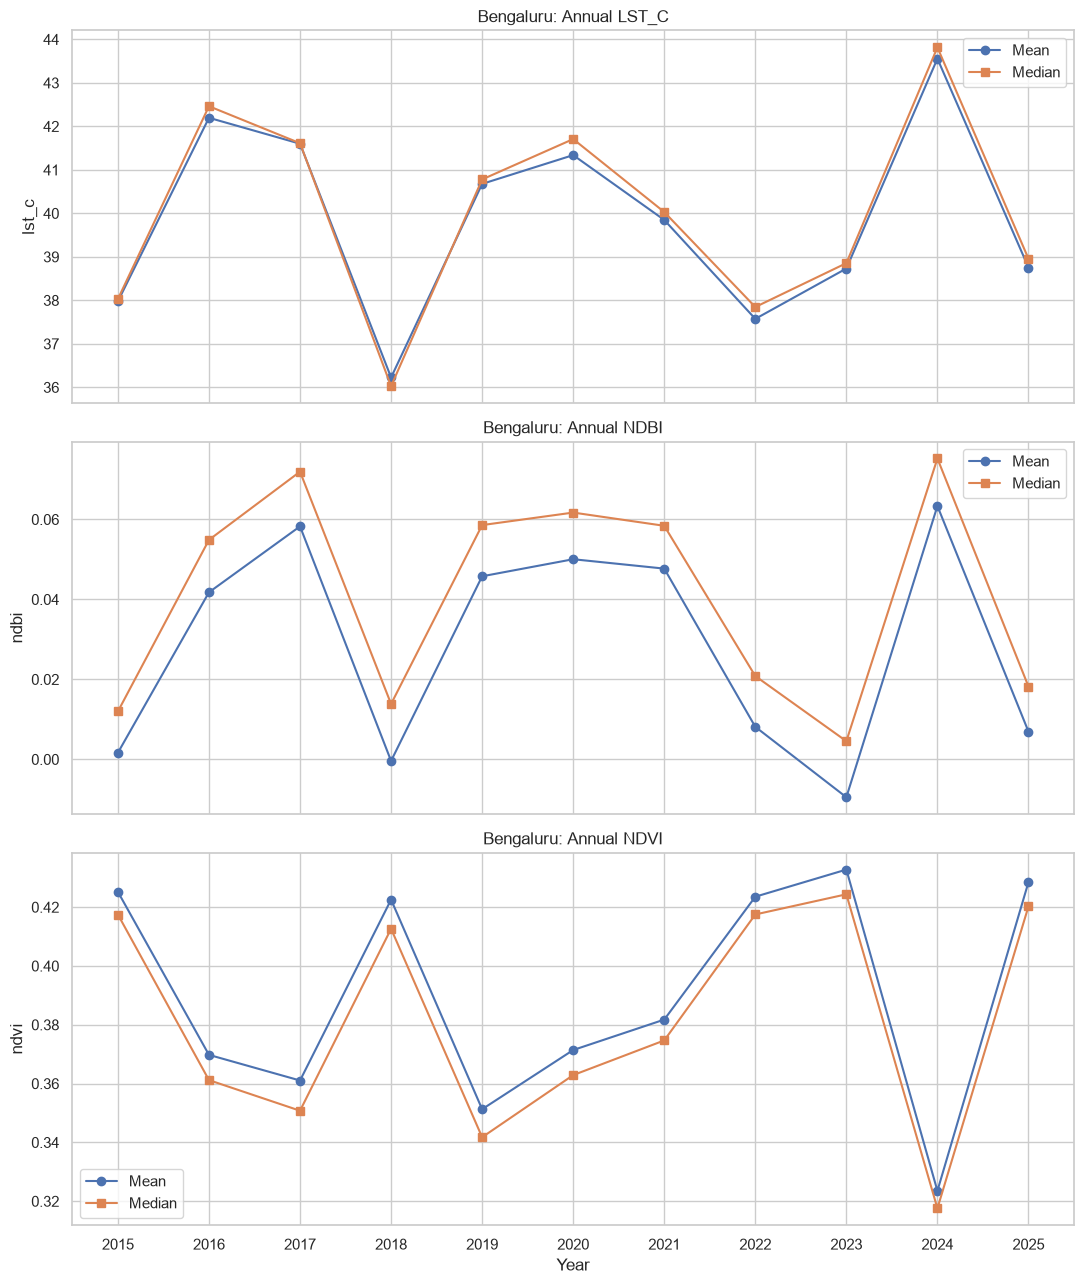

In [14]:

annual_stats = (
    data.groupby("year")[VARIABLES]
    .agg(["mean", "median", "std", "count"])
    .reindex(YEARS)
)

display(annual_stats)
annual_stats.to_csv(OUTPUT_DIR / "annual_summary_statistics.csv")

fig, axes = plt.subplots(3, 1, figsize=(11, 13), sharex=True)

for ax, variable in zip(axes, VARIABLES):
    stats = data.groupby("year")[variable].agg(["mean", "median"])

    ax.plot(stats.index, stats["mean"], marker="o", label="Mean")
    ax.plot(stats.index, stats["median"], marker="s", label="Median")

    ax.set_title(f"{CITY}: Annual {variable.upper()}")
    ax.set_ylabel(variable)
    ax.legend()

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(YEARS)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_annual_trends.png", dpi=200)
plt.show()


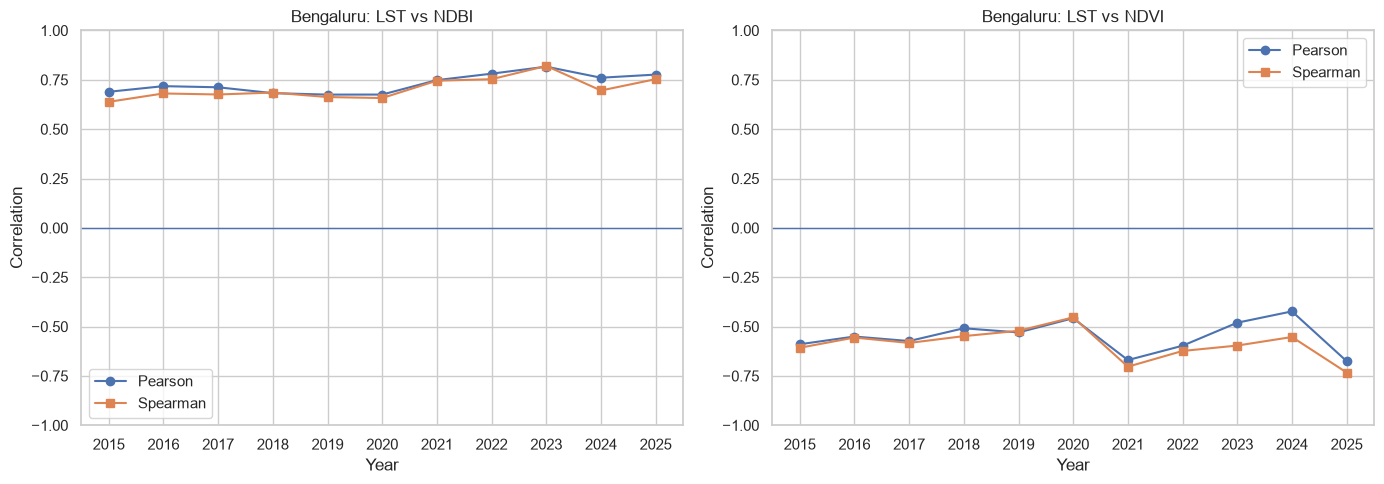

In [15]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, xvar, title in [
    (axes[0], "ndbi", "LST vs NDBI"),
    (axes[1], "ndvi", "LST vs NDVI")
]:
    subset = annual_corr[
        (annual_corr["variable_1"] == "lst_c") &
        (annual_corr["variable_2"] == xvar)
    ]

    ax.plot(
        subset["year"], subset["pearson_r"],
        marker="o", label="Pearson"
    )
    ax.plot(
        subset["year"], subset["spearman_rho"],
        marker="s", label="Spearman"
    )
    ax.axhline(0, linewidth=1)
    ax.set_title(f"{CITY}: {title}")
    ax.set_xlabel("Year")
    ax.set_ylabel("Correlation")
    ax.set_ylim(-1, 1)
    ax.set_xticks(YEARS)
    ax.legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_annual_correlations.png", dpi=200)
plt.show()


Grid columns: ['grid_id', 'in_frac', 'city_id', 'geometry']
Grid CRS: PROJCS["WGS 84 / World Cylindrical Equal Area",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433]],PROJECTION["Cylindrical_Equal_Area"],PARAMETER["central_meridian",0],PARAMETER["standard_parallel_1",30],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["m",1],AXIS["X",EAST],AXIS["Y",NORTH]]
Number of grid cells: 14440


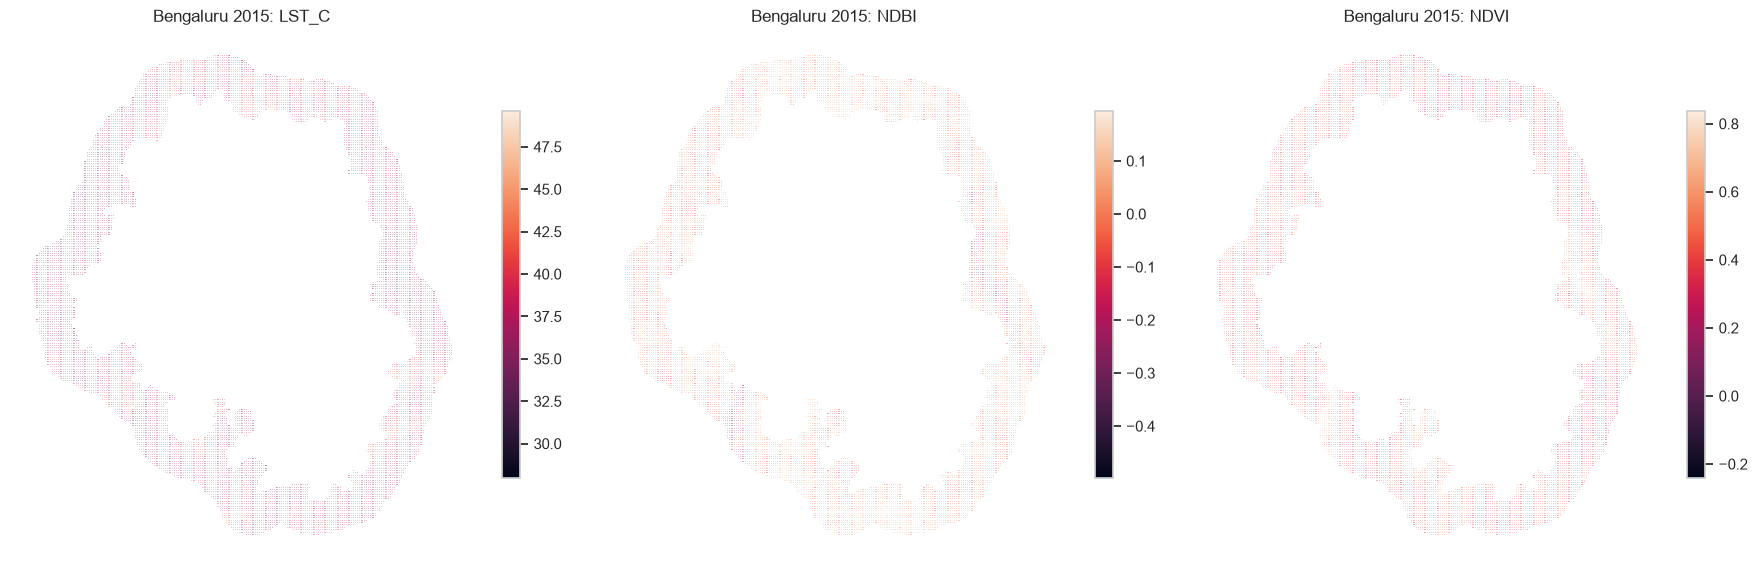

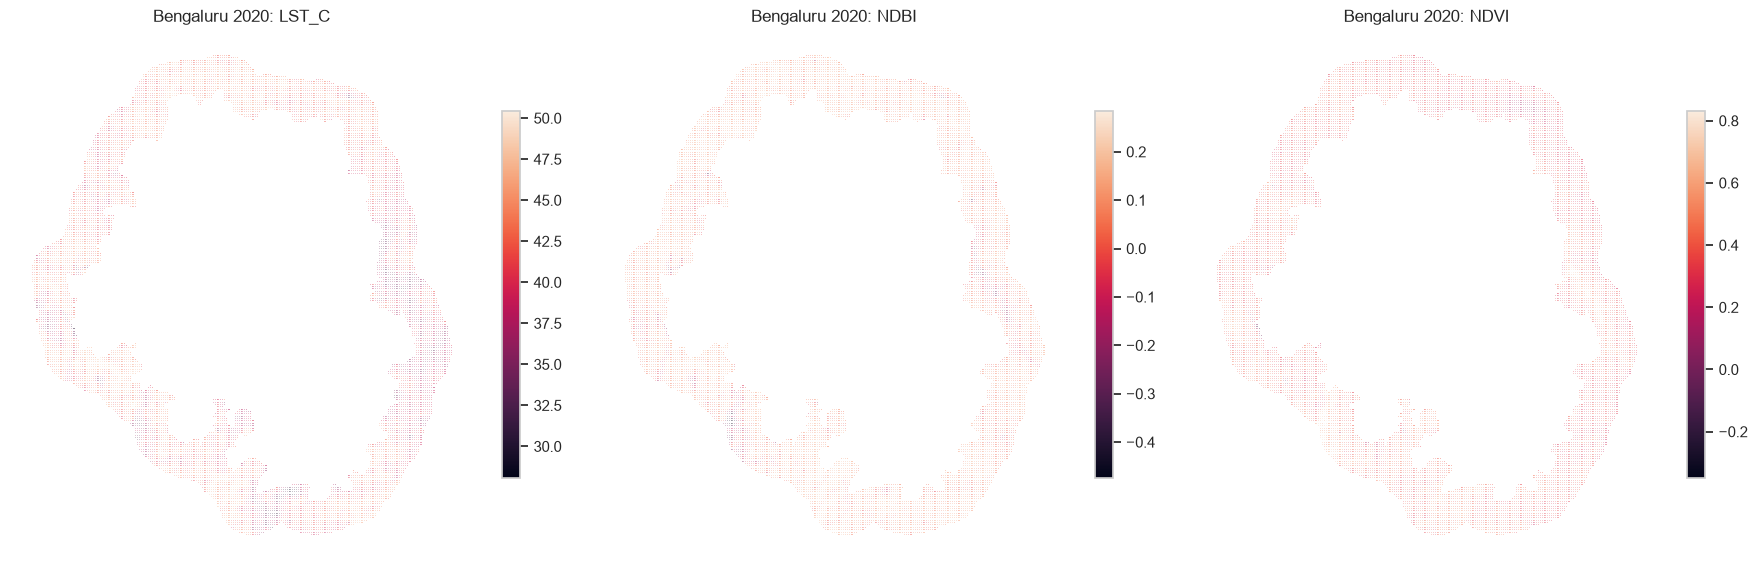

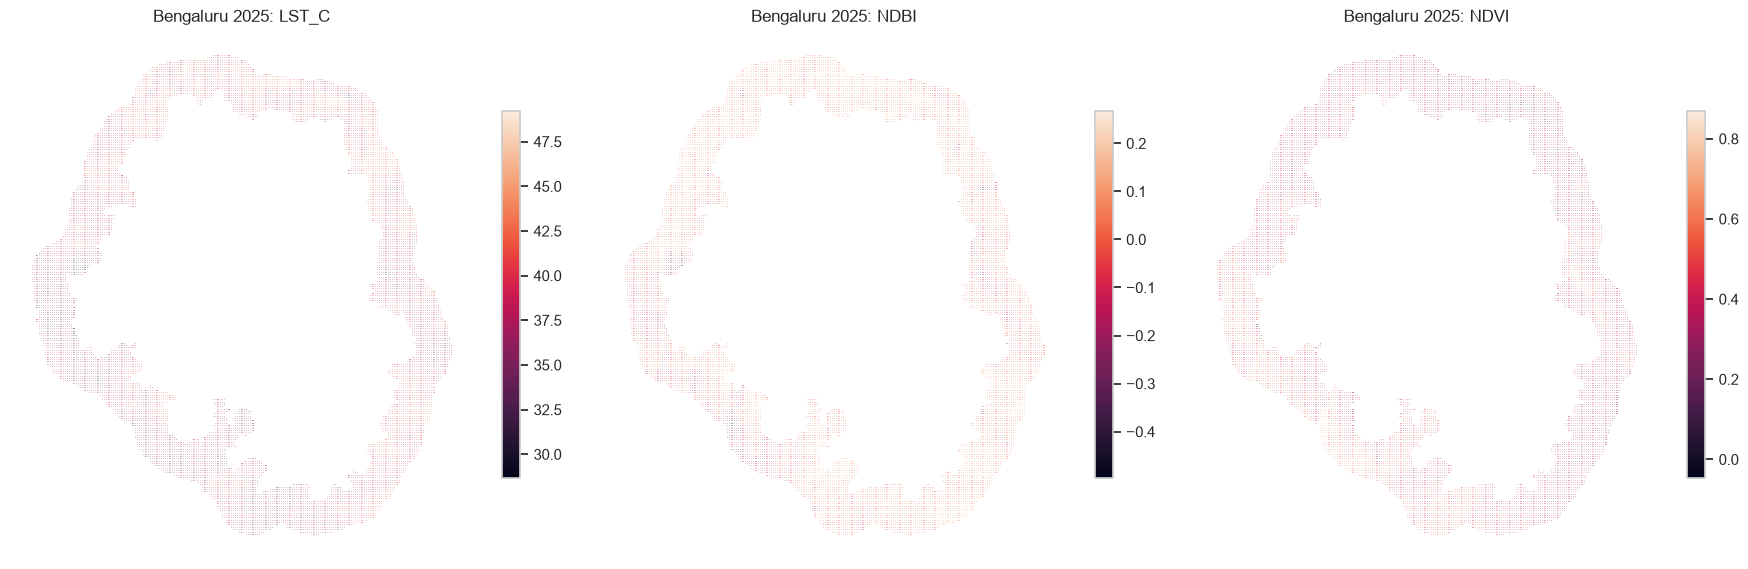

In [16]:

import geopandas as gpd
from pathlib import Path

# Change this path to your actual 300 m grid shapefile
SHAPEFILE_PATH = PROJECT_DIR / "grids" / f"{CITY}_Grid_300m.shp"

if not SHAPEFILE_PATH.exists():
    print(f"Shapefile not found: {SHAPEFILE_PATH}")
else:
    grid = gpd.read_file(SHAPEFILE_PATH)

    print("Grid columns:", grid.columns.tolist())
    print("Grid CRS:", grid.crs)
    print("Number of grid cells:", len(grid))

    if "grid_id" not in grid.columns:
        raise ValueError(
            "The shapefile has no grid_id column. "
            "Check its column names and identify the matching grid ID field."
        )

    grid["grid_id"] = grid["grid_id"].astype(str)
    data["grid_id"] = data["grid_id"].astype(str)

    if grid.crs is None:
        raise ValueError("The shapefile has no CRS defined.")

    grid = grid.to_crs("EPSG:4326")

    for year in MAP_YEARS:
        year_data = data.loc[
            data["year"] == year,
            ["grid_id"] + VARIABLES
        ]

        joined = grid.merge(
            year_data,
            on="grid_id",
            how="left",
            validate="one_to_one"
        )

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        for ax, variable in zip(axes, VARIABLES):
            joined.plot(
                column=variable,
                ax=ax,
                legend=True,
                missing_kwds={
                    "color": "lightgrey",
                    "label": "No data"
                },
                legend_kwds={"shrink": 0.65}
            )
            ax.set_title(f"{CITY} {year}: {variable.upper()}")
            ax.set_axis_off()

        plt.tight_layout()
        plt.savefig(
            OUTPUT_DIR / f"map_{CITY}_{year}.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
